<a href="https://colab.research.google.com/github/starsyntaxx/machine-learning-zoomcamp/blob/main/02_linear-regression/gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from zlib import crc32
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
from pandas.plotting import scatter_matrix

In [ ]:
def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()

/tmp/ipykernel_18631/1655008950.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  housing_tarball.extractall(path="datasets")


In [ ]:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

In [ ]:
splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(housing, housing["income_cat"]):
    strat_train_set_n = housing.iloc[train_index]
    strat_test_set_n = housing.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

In [ ]:
strat_train_set, strat_test_set = strat_splits[0]

In [ ]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

/tmp/ipykernel_18631/1299016719.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_.drop("income_cat", axis=1, inplace=True)
/tmp/ipykernel_18631/1299016719.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_.drop("income_cat", axis=1, inplace=True)


**DATA MODELLING**

In [ ]:
housing = strat_train_set.copy()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

In [ ]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN


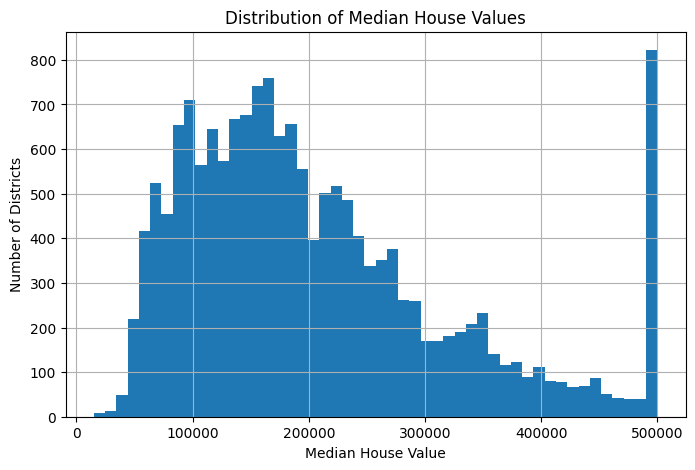

In [ ]:
# Plotting a histogram since train_labels is a Series and a scatter plot requires a 2D DataFrame
plt.figure(figsize=(8, 5))
housing['median_house_value'].hist(bins=50)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Number of Districts")
plt.grid(True)
plt.show()

In [ ]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 13096 to 19888
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16344 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   median_house_value  16512 non-null  float64
 9   ocean_proximity     16512 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.4+ MB


In [ ]:
# Prepare training features by dropping the target and 'ocean_proximity'
train_features = housing.drop(columns=["median_house_value", "ocean_proximity"])

# Prepare the target labels
y_train = housing["median_house_value"].copy()

# Display the features and labels shape to confirm
print("Features shape:", train_features.shape)
print("Labels shape:", y_train.shape)
display(train_features.head())

Features shape: (16512, 8)
Labels shape: (16512,)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292


In [ ]:
# Impute missing values in features (e.g., total_bedrooms has nulls)
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(train_features)

# Initialize the Linear Regression model
lin_reg = LinearRegression()

# Fit the model
lin_reg.fit(X_train, y_train)

# Make predictions on the training set
y_pred = lin_reg.predict(X_train)

# Calculate RMSE
lin_mse = mean_squared_error(y_train, y_pred)
lin_rmse = np.sqrt(lin_mse)
print("Training RMSE:", lin_rmse)

Training RMSE: 69188.09770628499


BaseLine RMSE IS 69188.097706

**BaseLine Two**

In [ ]:
housing_two = strat_train_set.copy()

In [ ]:
housing_two.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN


In [ ]:
categorical_features = housing_two[["ocean_proximity"]]
numerical_features = housing_two.drop(columns=["ocean_proximity", "train_labels"])

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Initialize the StandardScaler
scaler = StandardScaler()
encoder = OneHotEncoder()

# Scale the numerical features
numerical_features_scaled = scaler.fit_transform(numerical_features)

#Encode categorical features
categorical_features_encoded = encoder.fit_transform(categorical_features)

In [ ]:
categorical_features_encoded = pd.DataFrame(
    categorical_features_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features.columns),
    index=categorical_features.index
)
categorical_features_encoded

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
13096,0.0,0.0,0.0,1.0,0.0
14973,1.0,0.0,0.0,0.0,0.0
3785,0.0,1.0,0.0,0.0,0.0
14689,0.0,1.0,0.0,0.0,0.0
20507,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...
14207,1.0,0.0,0.0,0.0,0.0
13105,0.0,1.0,0.0,0.0,0.0
19301,0.0,0.0,0.0,0.0,1.0
19121,1.0,0.0,0.0,0.0,0.0


In [ ]:
# Convert the scaled numerical numpy array into a pandas DataFrame with matching index and columns
numerical_features_scaled_df = pd.DataFrame(
    numerical_features_scaled,
    columns=numerical_features.columns,
    index=numerical_features.index
)

# Safely concatenate both DataFrames side-by-side
prepared_features = pd.concat(
    [numerical_features_scaled_df, categorical_features_encoded],
    axis=1
)

print("Shape of prepared features:", prepared_features.shape)
prepared_features.head()

Shape of prepared features: (16512, 14)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.359094,0.137460,1.394812,-0.936491,2.185112,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.436356,-0.693771,-0.373485,1.171942,2.406254,1.0,0.0,0.0,0.0,0.0
3785,-1.203098,1.276119,0.351428,-0.712240,-0.759584,-0.788768,-0.775727,-0.759789,-0.907406,0.0,1.0,0.0,0.0,0.0
14689,1.231216,-0.884924,-0.919891,0.702262,0.736231,0.383175,0.731375,-0.850281,-0.955971,0.0,1.0,0.0,0.0,0.0
20507,0.711362,-0.875549,0.589800,0.790125,1.585590,0.444376,1.755263,-0.180365,1.348242,0.0,0.0,0.0,0.0,1.0


In [ ]:
# Prepare training features by dropping the target and 'ocean_proximity'
X_train_two = prepared_features.drop(columns=["median_house_value"])

# Prepare the target labels
y_train_two = housing_two['train_labels'].copy()

In [ ]:
X_train_two.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,168
population,0
households,0
median_income,0
ocean_proximity_<1H OCEAN,0
ocean_proximity_INLAND,0


In [ ]:
housing_two.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,train_labels
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY,13.035279
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN,13.089427
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND,11.529783
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND,11.473145
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN,12.798847


In [ ]:

# Impute missing values
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train_two)

# Initialize and train the model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train_two)

# Predict on the same training data
y_pred = lin_reg.predict(X_train)

# Calculate RMSE using the matching labels
lin_mse = mean_squared_error(y_train_two, y_pred)
lin_rmse = np.sqrt(lin_mse)

print("Training RMSE:", lin_rmse)


Training RMSE: 0.3280447742283167


In [ ]:
# 1. Un-log the predicted target values and the actual target values
y_pred_dollars = np.exp(y_pred)
y_train_dollars = np.exp(y_train_two)

# 2. Calculate the correct RMSE on the original dollar scale
lin_rmse_dollars = np.sqrt(mean_squared_error(y_train_dollars, y_pred_dollars))

print(f"Corrected RMSE on original scale: ${lin_rmse_dollars:,.2f}")

# 3. Compare the first 5 predictions directly in dollars
comparison_df = pd.DataFrame({
    "Actual (USD)": y_train_dollars,
    "Predicted (USD)": y_pred_dollars,
    "Difference (USD)": y_pred_dollars - y_train_dollars
})
display(comparison_df.head())

Corrected RMSE on original scale: $85,393.05


,Actual (USD),Predicted (USD),Difference (USD)
13096,458300.0,235499.708192,-222800.291808
14973,483800.0,321709.620755,-162090.379245
3785,101700.0,107953.334911,6253.334911
14689,96100.0,107785.277010,11685.277010
20507,361800.0,274426.568343,-87373.431657


### Inspecting the Learned Weights (Coefficients and Intercept)

We will examine the coefficients (weights) and bias (intercept) learned by both models. This tells us how much each feature contributes to the predicted house value.

In [ ]:
# 1. Weights for the model (lin_reg)
print("Model Weights and Intercept")
print(f"Intercept (Bias): {lin_reg.intercept_:.4f}\n")

# Pair each prepared feature name with its learned coefficient
for feature, coef in zip(X_train_two.columns, lin_reg.coef_):
    print(f"{feature:<30} : {coef:12.4f}")

Model Weights and Intercept
Intercept (Bias): 12.2822

longitude                      :      -0.3223
latitude                       :      -0.3345
housing_median_age             :       0.0298
total_rooms                    :      -0.0111
total_bedrooms                 :       0.1010
population                     :      -0.2218
households                     :       0.1667
median_income                  :       0.3164
ocean_proximity_<1H OCEAN      :      -0.0924
ocean_proximity_INLAND         :      -0.4005
ocean_proximity_ISLAND         :       0.7494
ocean_proximity_NEAR BAY       :      -0.1272
ocean_proximity_NEAR OCEAN     :      -0.1293


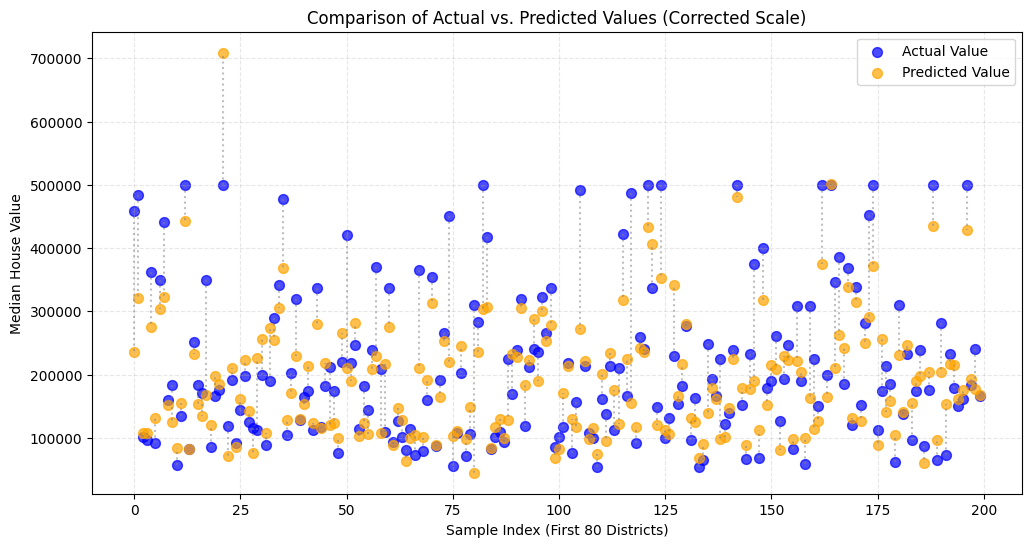

In [ ]:
# Compare a subset of actual and predicted values using different colors
plt.figure(figsize=(12, 6))

# Let's plot the first 80 samples for visual clarity
samples = 200
x_axis = range(samples)

plt.scatter(x_axis, y_train_dollars.iloc[:samples], color='blue', label='Actual Value', alpha=0.7, s=50)
plt.scatter(x_axis, y_pred_dollars[:samples], color='orange', label='Predicted Value', alpha=0.7, s=50)

# Add lines connecting the points to make comparisons even easier
plt.vlines(x_axis, y_train_dollars.iloc[:samples], y_pred_dollars[:samples], colors='gray', linestyles='dotted', alpha=0.5)

plt.xlabel("Sample Index (First 80 Districts)")
plt.ylabel("Median House Value")
plt.title("Comparison of Actual vs. Predicted Values (Corrected Scale)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

### Training a Polynomial Regression Model

To capture non-linear relationships, we will generate polynomial features (degree 2) from our prepared training set and fit a Linear Regression model to them.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# 1. Generate polynomial features (degree=2)
poly_features = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly = poly_features.fit_transform(X_train)

# 2. Train the Linear Regression model on polynomial features
poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train_two)

# 3. Predict on the training data (predictions are in log scale)
y_pred_poly_log = poly_reg.predict(X_train_poly)

# 4. Calculate the log-space RMSE
poly_mse_log = mean_squared_error(y_train_two, y_pred_poly_log)
poly_rmse_log = np.sqrt(poly_mse_log)
print(f"Polynomial Regression Log-scale RMSE: {poly_rmse_log:.4f}")

Polynomial Regression Log-scale RMSE: 0.2577


In [ ]:
# 5. Exponentiate predictions back to the original USD scale
y_pred_poly_dollars = np.exp(y_pred_poly_log)

# 6. Calculate corrected RMSE on the original dollar scale
poly_rmse_dollars = np.sqrt(mean_squared_error(y_train_dollars, y_pred_poly_dollars))
print(f"Polynomial Regression RMSE on original scale: ${poly_rmse_dollars:,.2f}")
print(f"Difference from Linear Regression baseline: ${lin_rmse_dollars - poly_rmse_dollars:,.2f} improvement")

Polynomial Regression RMSE on original scale: $55,349.23
Difference from Linear Regression baseline: $30,043.81 improvement
